# Nile Connect - Telecom Customer Intelligence
## Part 6: Market Basket Analysis & Association Rules (Apriori)
**Data Source:** `service_transactions.csv` (12,993 purchase events, 4,500 baskets, 13 services)  
**Business Question (CEO Question 4):** *"Our bundles are random. Which services do people buy together?"*

---
### Objectives:
1. **Preprocessing & Audit:** Clean transactions and reshape into a transaction basket matrix (`True/False`).
2. **Exploratory Visualizations:** Analyze basket size distributions and service co-occurrences.
3. **6.2 Top Popular Services:** Identify and visualize the top 5 services by support.
4. **6.3 Apriori & Association Rules:** Mine frequent itemsets (`min_support = 0.03`) and generate high-confidence rules (`min_confidence = 0.5`) sorted by `lift`.
5. **6.4 Conceptual Analysis:** Explain Support, Confidence, and Lift with real rules, and analyze why high-confidence rules with Lift $\approx 1$ lack business value.
6. **6.5 Actionable Commercial Bundles:** Formulate 3 concrete commercial bundles tailored for Monday morning rollout.
7. **Bonus Recommender System:** Implement an Item-Item Cosine Similarity Recommender Engine.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.metrics.pairwise import cosine_similarity
import warnings
warnings.filterwarnings('ignore')

# Visual style setup
sns.set_theme(style='whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10


In [2]:
# Load service transactions
df_trans = pd.read_csv('../Original_Data/service_transactions.csv')

print("=== DATASET OVERVIEW ===")
print(f"Total Rows (Service purchases): {df_trans.shape[0]:,}")
print(f"Total Columns: {df_trans.shape[1]}")
print(f"Unique Transactions (Baskets): {df_trans['transaction_id'].nunique():,}")
print(f"Unique Services Offered: {df_trans['service'].nunique()}")
print(f"Missing Values: {df_trans.isna().sum().sum()}")
print(f"Exact Duplicate Rows: {df_trans.duplicated().sum()}")
print(f"Duplicate service in same transaction: {df_trans.duplicated(subset=['transaction_id', 'service']).sum()}")

df_trans.head(10)


=== DATASET OVERVIEW ===
Total Rows (Service purchases): 12,993
Total Columns: 2
Unique Transactions (Baskets): 4,500
Unique Services Offered: 13
Missing Values: 0
Exact Duplicate Rows: 0
Duplicate service in same transaction: 0


,transaction_id,service
0,T02071,Extra_Minutes
1,T03753,Roaming_Pack
2,T02047,Cloud_Storage
3,T00394,Home_Internet
4,T02490,Extra_Minutes
5,T01012,Router_Upgrade
6,T02890,Router_Upgrade
7,T03848,Home_Internet
8,T02760,Mobile_Wallet
9,T04010,Mobile_Data_Pack


In [3]:
# Calculate basket sizes (number of services per transaction)
basket_sizes = df_trans.groupby('transaction_id')['service'].count()

print("=== BASKET SIZE SUMMARY ===")
print(basket_sizes.describe())
print(f"\nMedian basket size: {basket_sizes.median():.0f} services")
print(f"Baskets with 1 service: {(basket_sizes == 1).sum()} ({(basket_sizes == 1).mean()*100:.1f}%)")
print(f"Baskets with multi-services (>=2): {(basket_sizes >= 2).sum()} ({(basket_sizes >= 2).mean()*100:.1f}%)")


=== BASKET SIZE SUMMARY ===
count    4500.000000
mean        2.887333
std         1.771817
min         1.000000
25%         1.000000
50%         3.000000
75%         4.000000
max        11.000000
Name: service, dtype: float64

Median basket size: 3 services
Baskets with 1 service: 1336 (29.7%)
Baskets with multi-services (>=2): 3164 (70.3%)


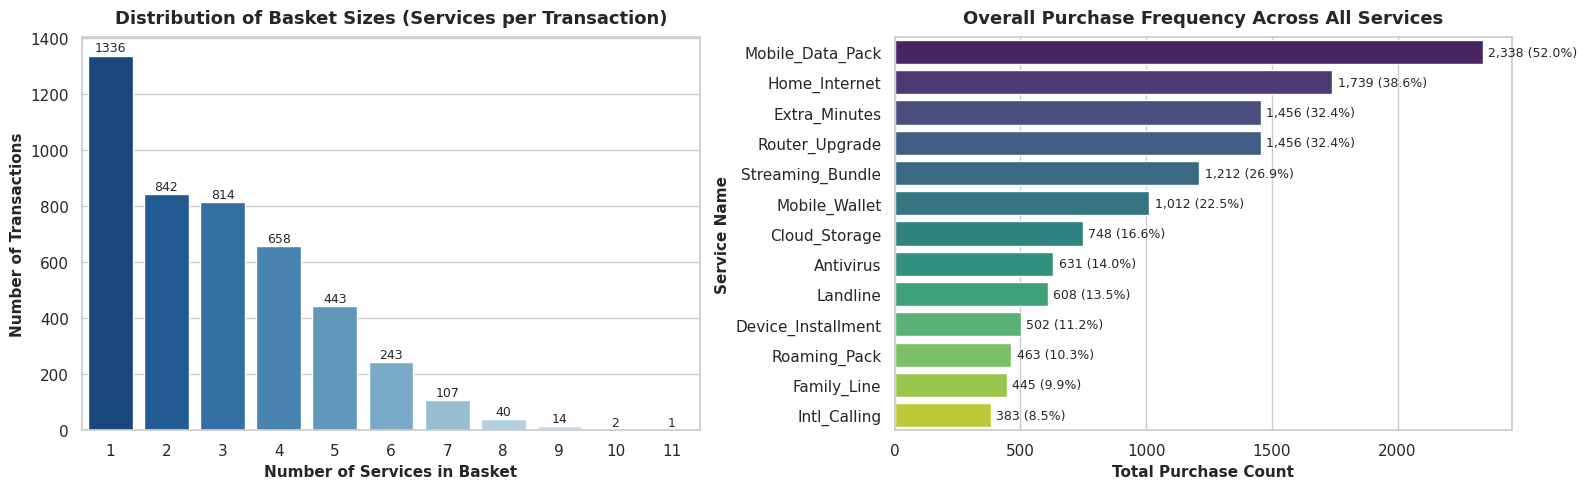

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Basket Size Distribution
sns.countplot(x=basket_sizes, ax=axes[0], palette='Blues_r')
axes[0].set_title('Distribution of Basket Sizes (Services per Transaction)', fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel('Number of Services in Basket', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Number of Transactions', fontsize=11, fontweight='bold')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='baseline', fontsize=9, xytext=(0, 3), textcoords='offset points')

# 2. Overall Service Purchase Frequencies
service_counts = df_trans['service'].value_counts()
sns.barplot(x=service_counts.values, y=service_counts.index, ax=axes[1], palette='viridis')
axes[1].set_title('Overall Purchase Frequency Across All Services', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('Total Purchase Count', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Service Name', fontsize=11, fontweight='bold')
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_width()):,} ({p.get_width()/len(basket_sizes)*100:.1f}%)', 
                     (p.get_width(), p.get_y() + p.get_height() / 2.),
                     ha='left', va='center', fontsize=9, xytext=(4, 0), textcoords='offset points')

plt.tight_layout()
plt.show()


In [5]:
# =======================================================
# 6.1 Reshape into Basket Table (One-Hot Encoded Boolean Matrix)
# =======================================================
# Create binary crosstab: True if service was purchased in transaction, False otherwise
basket = pd.crosstab(df_trans['transaction_id'], df_trans['service']) > 0

print(f"Basket Table Shape: {basket.shape[0]} transactions × {basket.shape[1]} services")
print(f"Data types: All boolean ({basket.dtypes.unique()})")
print("\nFirst 5 transactions in Basket Format:")
basket.head()


Basket Table Shape: 4500 transactions × 13 services
Data types: All boolean ([dtype('bool')])

First 5 transactions in Basket Format:


service,Antivirus,Cloud_Storage,Device_Installment,Extra_Minutes,Family_Line,Home_Internet,Intl_Calling,Landline,Mobile_Data_Pack,Mobile_Wallet,Roaming_Pack,Router_Upgrade,Streaming_Bundle
transaction_id,,,,,,,,,,,,,
T00001,False,False,False,True,False,True,True,False,True,True,True,True,True
T00002,False,False,False,True,False,False,False,False,False,False,False,False,False
T00003,False,True,False,False,True,True,True,True,True,False,True,False,False
T00004,False,False,False,True,False,False,False,False,False,False,False,False,False
T00005,False,False,False,False,False,False,False,False,True,False,False,False,False


Top 5 Services by Support:
1. Mobile_Data_Pack    : Support = 0.5196 (51.96%) | 2,338 transactions
2. Home_Internet       : Support = 0.3864 (38.64%) | 1,739 transactions
3. Router_Upgrade      : Support = 0.3236 (32.36%) | 1,456 transactions
4. Extra_Minutes       : Support = 0.3236 (32.36%) | 1,456 transactions
5. Streaming_Bundle    : Support = 0.2693 (26.93%) | 1,212 transactions


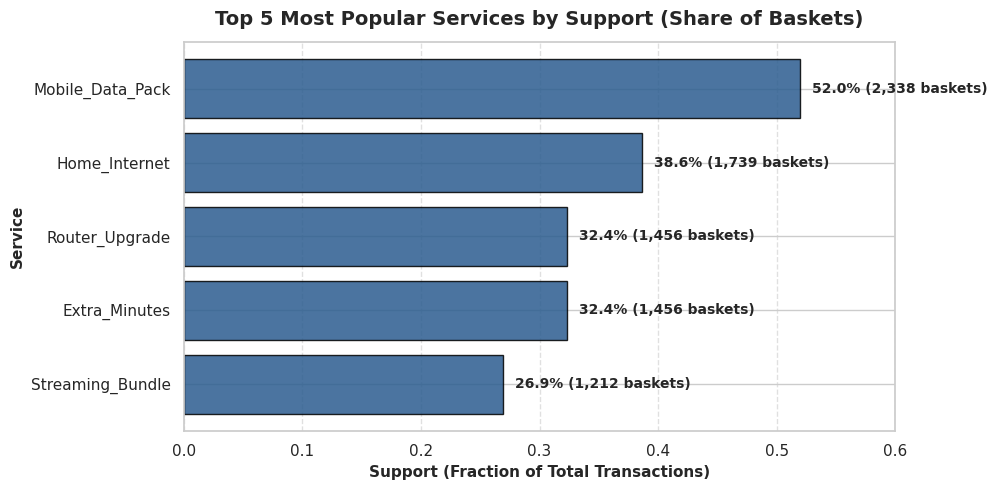

In [6]:
# =======================================================
# 6.2 Top 5 Most Popular Services & Support Plot
# =======================================================
# Calculate Support for each service: Support(Item) = Count(Item) / Total_Transactions
service_support = basket.mean().sort_values(ascending=False)
top_5_services = service_support.head(5)

print("Top 5 Services by Support:")
for rank, (svc, supp) in enumerate(top_5_services.items(), 1):
    count = basket[svc].sum()
    print(f"{rank}. {svc:<20}: Support = {supp:.4f} ({supp*100:.2f}%) | {count:,} transactions")

# Plot Top 5 Services Support
plt.figure(figsize=(10, 5))
bars = plt.barh(top_5_services.index[::-1], top_5_services.values[::-1], color='#2b5c8f', edgecolor='black', alpha=0.85)
plt.title('Top 5 Most Popular Services by Support (Share of Baskets)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Support (Fraction of Total Transactions)', fontsize=11, fontweight='bold')
plt.ylabel('Service', fontsize=11, fontweight='bold')
plt.xlim(0, 0.60)
plt.grid(axis='x', linestyle='--', alpha=0.6)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.01, bar.get_y() + bar.get_height()/2, f'{w*100:.1f}% ({int(w*len(basket)):,} baskets)', 
             va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


In [7]:
# =======================================================
# 6.3 Mine Frequent Itemsets (Apriori) & Build Rules
# =======================================================
# 1. Run Apriori with min_support = 0.03
frequent_itemsets = apriori(basket, min_support=0.03, use_colnames=True)
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(lambda x: len(x))

print(f"Total Frequent Itemsets found (min_support >= 0.03): {len(frequent_itemsets)}")
print(f"- 1-itemsets: {(frequent_itemsets['length'] == 1).sum()}")
print(f"- 2-itemsets: {(frequent_itemsets['length'] == 2).sum()}")
print(f"- 3-itemsets: {(frequent_itemsets['length'] == 3).sum()}")
print(f"- 4-itemsets: {(frequent_itemsets['length'] == 4).sum()}")

# 2. Build Association Rules with min_confidence = 0.5
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.5)

# Convert frozensets to readable string representations
rules['antecedents_str'] = rules['antecedents'].apply(lambda x: ', '.join(list(x)))
rules['consequents_str'] = rules['consequents'].apply(lambda x: ', '.join(list(x)))
rules['rule_str'] = rules['antecedents_str'] + ' -> ' + rules['consequents_str']

# Sort rules by Lift descending
rules_sorted = rules.sort_values(by='lift', ascending=False).reset_index(drop=True)

print(f"\nTotal Association Rules Generated (min_confidence >= 0.5): {len(rules_sorted)}")
print(f"Max Lift achieved: {rules_sorted['lift'].max():.2f}")
print(f"Min Lift achieved: {rules_sorted['lift'].min():.2f}")

# Display top 15 rules sorted by Lift
display_cols = ['rule_str', 'support', 'confidence', 'lift', 'leverage', 'conviction']
print("\n=== TOP 15 RULES SORTED BY LIFT ===")
rules_sorted[display_cols].head(15)


Total Frequent Itemsets found (min_support >= 0.03): 109
- 1-itemsets: 13
- 2-itemsets: 46
- 3-itemsets: 40
- 4-itemsets: 10

Total Association Rules Generated (min_confidence >= 0.5): 112
Max Lift achieved: 13.39
Min Lift achieved: 0.97

=== TOP 15 RULES SORTED BY LIFT ===


,rule_str,support,confidence,lift,leverage,conviction
0,"Router_Upgrade, Device_Installment -> Antiviru...",0.030667,0.797688,13.394013,0.028377,4.648483
1,"Antivirus, Home_Internet -> Router_Upgrade, De...",0.030667,0.514925,13.394013,0.028377,1.982284
2,"Antivirus, Router_Upgrade -> Home_Internet, De...",0.030667,0.641860,13.372093,0.028373,2.658182
3,"Home_Internet, Device_Installment -> Antivirus...",0.030667,0.638889,13.372093,0.028373,2.636923
4,"Home_Internet, Roaming_Pack -> Intl_Calling",0.034000,0.776650,9.125128,0.030274,4.096207
5,"Intl_Calling, Mobile_Data_Pack -> Roaming_Pack",0.040444,0.938144,9.118033,0.036009,14.503296
6,"Intl_Calling, Home_Internet -> Roaming_Pack",0.034000,0.932927,9.067323,0.030250,13.375111
7,"Mobile_Data_Pack, Roaming_Pack -> Intl_Calling",0.040444,0.771186,9.060937,0.035981,3.998403
8,Intl_Calling -> Roaming_Pack,0.078444,0.921671,8.957926,0.069687,11.453119
9,Roaming_Pack -> Intl_Calling,0.078444,0.762419,8.957926,0.069687,3.850851


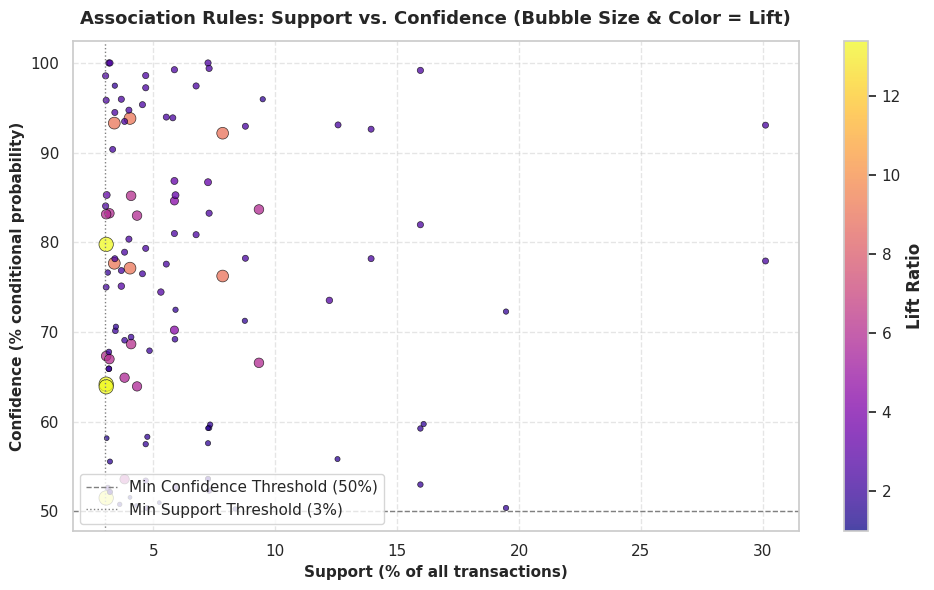

In [8]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(rules_sorted['support']*100, rules_sorted['confidence']*100, 
                      c=rules_sorted['lift'], cmap='plasma', s=rules_sorted['lift']*8, 
                      alpha=0.75, edgecolors='black', linewidth=0.5)

plt.title('Association Rules: Support vs. Confidence (Bubble Size & Color = Lift)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Support (% of all transactions)', fontsize=11, fontweight='bold')
plt.ylabel('Confidence (% conditional probability)', fontsize=11, fontweight='bold')
plt.axhline(50, color='grey', linestyle='--', linewidth=1, label='Min Confidence Threshold (50%)')
plt.axvline(3, color='grey', linestyle=':', linewidth=1, label='Min Support Threshold (3%)')

cbar = plt.colorbar(scatter)
cbar.set_label('Lift Ratio', fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.show()


### 6.4 Association Rules Metrics Explained (Real-World Analysis)

#### 1. Definitions with a Real Rule:
Let us analyze the real mined rule:
$$\text{Intl\_Calling} \longrightarrow \text{Roaming\_Pack}$$
- **Support (0.0784 or 7.84%):**  
  Measures the overall popularity of the combined bundle. Out of all 4,500 transactions, exactly **353 baskets (7.84%)** contained **both** `Intl_Calling` and `Roaming_Pack`.
- **Confidence (0.9217 or 92.17%):**  
  Measures the conditional probability $P(\text{Roaming\_Pack} \mid \text{Intl\_Calling})$. When a customer purchases `Intl_Calling`, there is a **92.17% probability** that they will also add `Roaming_Pack` to their basket.
- **Lift (8.96):**  
  Measures the strength of the association compared to pure random chance:
  $$\text{Lift}(A \to B) = \frac{\text{Confidence}(A \to B)}{\text{Support}(B)} = \frac{0.9217}{0.1029} = 8.96$$
  Customers who buy `Intl_Calling` are **almost 9 times more likely** to purchase `Roaming_Pack` than a typical random customer.

---

#### 2. Answer to PDF Question: *"Why is a rule with high confidence but lift near 1 not interesting?"*
Consider the real rule from our table:
$$\text{Roaming\_Pack} \longrightarrow \text{Mobile\_Data\_Pack} \quad (\text{Confidence} = 50.97\%, \quad \text{Lift} = 0.981)$$

- **Why it looks deceptive:** The confidence is above **50%**, which might trick a novice into thinking that *"half the people buying Roaming Packs also buy Mobile Data Packs!"*
- **Why it has zero commercial value (Lift $\approx 1$):**  
  The overall baseline support for `Mobile_Data_Pack` across all Nile Connect customers is **51.96%**. Therefore, knowing that a customer purchased `Roaming_Pack` gives us **zero new predictive information**:
  $$P(\text{Mobile\_Data\_Pack} \mid \text{Roaming\_Pack}) = 50.97\% \approx P(\text{Mobile\_Data\_Pack}) = 51.96\%$$
  Since $\text{Lift} = 0.981 \approx 1$, the two purchases are **statistically independent**. High confidence here is simply an artifact of `Mobile_Data_Pack` being a mass-market staple, not an organic affinity. Wasting promotional budget or marketing discounts on rules with Lift $\le 1.0$ produces no incremental revenue.


### 6.5 Top 3 Actionable Commercial Bundles (Rollout Strategy)

Based on our association rules, Nile Connect should immediately replace its unsegmented, random promotions with the following 3 high-affinity commercial bundles:

---

#### Bundle 1: "Nile Global Jetsetter Pass" (The Traveler Bundle)
* **Underlying Rule:** `Intl_Calling` $\longleftrightarrow$ `Roaming_Pack`  
  *(Support = 7.84%, Confidence = 92.17%, Lift = **8.96**)*
* **Commercial Offer:**  
  *"Subscribe to our International Calling bundle (60 mins) and get an automatic 40% discount on your next 7-day Worldwide Roaming Data Pass!"*
* **Target Audience:** Business travelers, frequent fliers, and expatriates (matches Segment 3 from Part 5).
* **Business Rationale:** 92% of international callers need roaming. Packaging them proactively prevents customers from buying local SIM cards at destination airports.

---

#### Bundle 2: "Nile Smart Home Ultra Connect" (The Broadband Bundle)
* **Underlying Rule:** `Router_Upgrade` $\longleftrightarrow$ `Home_Internet`  
  *(Support = 30.11%, Confidence = 93.06%, Lift = **2.41**)*
* **Commercial Offer:**  
  *"Upgrade to our Home Internet Fiber plan (140+ GB) and receive a high-speed Dual-Band WiFi-6 Router Upgrade with 0 EGP upfront down-payment (or free installment on annual contracts)!"*
* **Target Audience:** Home internet subscribers, families, and high-bandwidth households.
* **Business Rationale:** This is the highest volume affinity pair in the company (1,355 transactions). Removing friction from router hardware upgrades reduces customer dissatisfaction and Wi-Fi buffering complaints.

---

#### Bundle 3: "Nile Total Device Shield & Care" (The Hardware Security Bundle)
* **Underlying Rule:** `Device_Installment` $\longleftrightarrow$ `Antivirus`  
  *(Support = 9.33%, Confidence = 83.67%, Lift = **5.97**)*
* **Commercial Offer:**  
  *"Purchase any new smartphone via Nile Device Installments and receive a complimentary 6-month premium Antivirus & Cyber-Security license plus screen damage insurance!"*
* **Target Audience:** Customers buying new mobile handsets on credit.
* **Business Rationale:** Over 83% of phone installment buyers willingly add antivirus software. Bundling security hardware financing establishes trust and builds recurring software attachment rates.


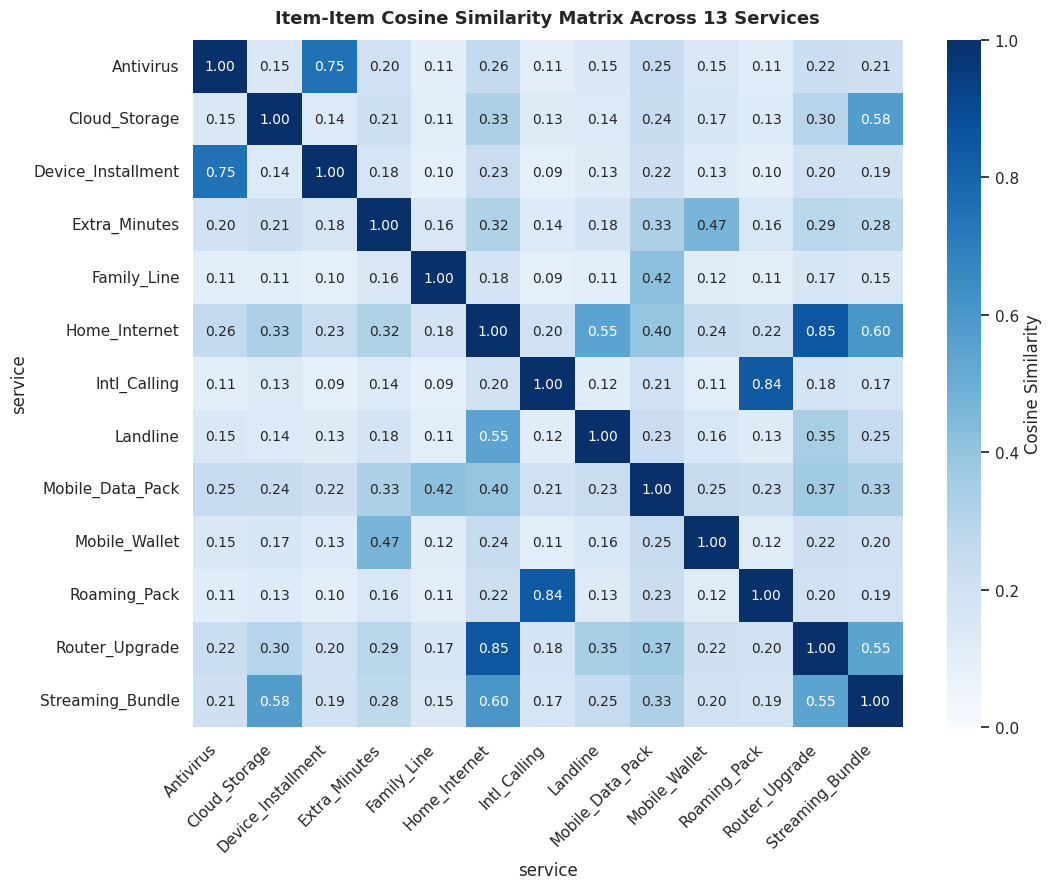

=== Next-Best-Offer Recommendations for Customers Buying 'Home_Internet' ===
 1. Recommend: Router_Upgrade       | Affinity Score: 0.852
 2. Recommend: Streaming_Bundle     | Affinity Score: 0.603

=== Next-Best-Offer Recommendations for Customers Buying 'Intl_Calling' ===
 1. Recommend: Roaming_Pack         | Affinity Score: 0.838
 2. Recommend: Mobile_Data_Pack     | Affinity Score: 0.205

=== Next-Best-Offer Recommendations for Customers Buying 'Device_Installment' ===
 1. Recommend: Antivirus            | Affinity Score: 0.746
 2. Recommend: Home_Internet        | Affinity Score: 0.231

=== Next-Best-Offer Recommendations for Customers Buying 'Streaming_Bundle' ===
 1. Recommend: Home_Internet        | Affinity Score: 0.603
 2. Recommend: Cloud_Storage        | Affinity Score: 0.578



In [9]:
# =======================================================
# BONUS: Item-Item Cosine Similarity Recommender Engine
# =======================================================
# Compute item-item cosine similarity on the transaction basket matrix
item_similarity = cosine_similarity(basket.T)
sim_df = pd.DataFrame(item_similarity, index=basket.columns, columns=basket.columns)

# Plot Cosine Similarity Heatmap
plt.figure(figsize=(11, 9))
sns.heatmap(sim_df, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar_kws={'label': 'Cosine Similarity'})
plt.title('Item-Item Cosine Similarity Matrix Across 13 Services', fontsize=13, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Intelligent Recommendation Function
def recommend_services(service_name, top_n=2):
    if service_name not in sim_df.columns:
        return f"Service '{service_name}' not found."
    
    similar_services = sim_df[service_name].drop(service_name).sort_values(ascending=False).head(top_n)
    print(f"=== Next-Best-Offer Recommendations for Customers Buying '{service_name}' ===")
    for rank, (svc, score) in enumerate(similar_services.items(), 1):
        print(f" {rank}. Recommend: {svc:<20} | Affinity Score: {score:.3f}")
    print()

# Test recommendations for core products
recommend_services('Home_Internet')
recommend_services('Intl_Calling')
recommend_services('Device_Installment')
recommend_services('Streaming_Bundle')
